<a href="https://colab.research.google.com/github/kimnguyen02/Module4_ITAI2372/blob/main/Module_4_Kim_Nguyen_ITAI_2372.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pandas nltk matplotlib seaborn

- pandas: loads and organizes news records.
- nltk: provides the VADER sentiment analyzer.
- matplotlib and seaborn: help us visualize the results.

## Load the data

In [2]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

# Find the uploaded JSON file
filename = next(
    name for name in uploaded
    if name.endswith(".json")
)

# The dataset is JSON Lines: one JSON object per line
df = pd.read_json(
    io.BytesIO(uploaded[filename]),
    lines=True
)

print("Dataset loaded successfully!")
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Saving News_Category_Dataset_v3.json to News_Category_Dataset_v3.json
Dataset loaded successfully!
Number of rows: 209527
Number of columns: 6

Column names:
['link', 'headline', 'category', 'short_description', 'authors', 'date']


,link,headline,category,short_description,authors,date
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22


In [3]:
# Check column types and missing values
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nNumber of unique categories:", df["category"].nunique())

print("\nNews articles per category:")
print(df["category"].value_counts().head(15))

print("\nExample headlines:")
for headline in df["headline"].head(5):
    print("-", headline)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209527 entries, 0 to 209526
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   link               209527 non-null  object        
 1   headline           209527 non-null  object        
 2   category           209527 non-null  object        
 3   short_description  209527 non-null  object        
 4   authors            209527 non-null  object        
 5   date               209527 non-null  datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 9.6+ MB

Missing values per column:
link                 0
headline             0
category             0
short_description    0
authors              0
date                 0
dtype: int64

Number of unique categories: 42

News articles per category:
category
POLITICS          35602
WELLNESS          17945
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9814
PARENTING    

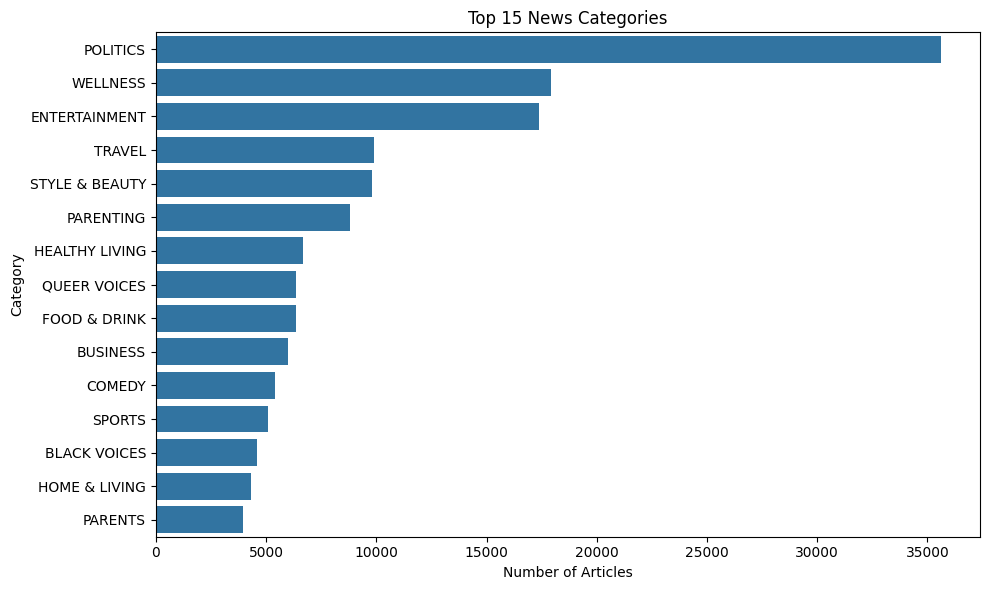

In [4]:
# Visulize the top categories
import matplotlib.pyplot as plt
import seaborn as sns

top_categories = df["category"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title("Top 15 News Categories")
plt.xlabel("Number of Articles")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

## Combine Headline and Description
Description can provide context that helps sentiment analysis

In [5]:
import pandas as pd

# Make sure missing text fields don't cause errors
df["headline"] = df["headline"].fillna("").astype(str)
df["short_description"] = df["short_description"].fillna("").astype(str)

# Combine the two fields for analysis
df["text"] = (
    df["headline"].str.strip()
    + ". "
    + df["short_description"].str.strip()
).str.strip()

# Remove records with no usable text
df = df[df["text"].str.len() > 0].copy()

print("Articles with usable text:", len(df))
df[["category", "headline", "text"]].head()

Articles with usable text: 209527


,category,headline,text
0,U.S. NEWS,Over 4 Million Americans Roll Up Sleeves For O...,Over 4 Million Americans Roll Up Sleeves For O...
1,U.S. NEWS,"American Airlines Flyer Charged, Banned For Li...","American Airlines Flyer Charged, Banned For Li..."
2,COMEDY,23 Of The Funniest Tweets About Cats And Dogs ...,23 Of The Funniest Tweets About Cats And Dogs ...
3,PARENTING,The Funniest Tweets From Parents This Week (Se...,The Funniest Tweets From Parents This Week (Se...
4,U.S. NEWS,Woman Who Called Cops On Black Bird-Watcher Lo...,Woman Who Called Cops On Black Bird-Watcher Lo...


### Filter finance-related articles

In [6]:
import re

finance_keywords = [
    "stock market", "stock price", "stocks", "shares", "share price",
    "wall street", "nasdaq", "s&p 500", "dow jones",
    "earnings", "quarterly results", "revenue", "profit", "losses",
    "investor", "investors", "investment", "investing",
    "bank", "banking", "interest rate", "federal reserve",
    "inflation", "recession", "economic growth", "unemployment",
    "cryptocurrency", "bitcoin", "ethereum", "crypto",
    "ipo", "merger", "acquisition", "dividend", "bond market",
    "oil prices", "commodity prices", "exchange rate",
    "financial markets", "hedge fund", "private equity",
    "mortgage rates", "credit market", "corporate debt"
]

# Escape special characters in keywords and match whole phrases/words
pattern = r"\b(?:" + "|".join(
    re.escape(keyword) for keyword in finance_keywords
) + r")\b"

# Search both headlines and descriptions
finance_mask = df["text"].str.contains(
    pattern,
    case=False,
    regex=True,
    na=False
)

finance_df = df.loc[finance_mask].copy()

print("Total articles:", len(df))
print("Finance-related candidates:", len(finance_df))
print("Percentage selected:", round(100 * len(finance_df) / len(df), 2), "%")

finance_df[["date", "category", "headline", "short_description"]].head(20)

Total articles: 209527
Finance-related candidates: 3291
Percentage selected: 1.57 %


,date,category,headline,short_description
4,2022-09-22,U.S. NEWS,Woman Who Called Cops On Black Bird-Watcher Lo...,Amy Cooper accused investment firm Franklin Te...
56,2022-09-13,U.S. NEWS,U.S. Inflation Falls For 2nd Straight Month On...,"On a monthly basis, prices rose 0.1%, after a ..."
91,2022-09-07,POLITICS,The Unemployment Insurance System Is Not Ready...,"States are cutting back, and Congress is unlik..."
121,2022-09-02,U.S. NEWS,U.S. Hiring Slowed In August As Employers Add ...,"The unemployment rate rose to 3.7%, from a hal..."
133,2022-08-30,POLITICS,Stocks Dive For Truth Social SPAC Amid Merger ...,It's one thing after another for Donald Trump'...
169,2022-08-24,POLITICS,IRS Launches Safety Review Amid Threats To Wor...,The Internal Revenue Service says it is conduc...
223,2022-08-14,WORLD NEWS,Palestinian Gunman Wounds 8 In Late-Night Jeru...,The attack in Jerusalem followed a tense week ...
230,2022-08-13,POLITICS,Sinema Took Wall Street Money While Killing Ta...,Democratic Sen. Kyrsten Sinema of Arizona has ...
237,2022-08-12,POLITICS,Democrats’ Inflation Reduction Act Expected To...,The bill was also touted as lowering the defic...
242,2022-08-11,U.S. NEWS,U.S. Unemployment Claims Rise To Highest Level...,"Applications for jobless aid climbed by 14,000..."


In [7]:
print("Selected articles by original category:")
print(finance_df["category"].value_counts().head(15))

print("\nSample selected headlines:")
for headline in finance_df["headline"].head(20):
    print("-", headline)

Selected articles by original category:
category
BUSINESS          749
POLITICS          649
MONEY             253
ENTERTAINMENT     217
WELLNESS          166
IMPACT            111
TECH               80
BLACK VOICES       67
TRAVEL             67
WORLDPOST          62
STYLE & BEAUTY     61
HOME & LIVING      55
PARENTING          52
MEDIA              51
COMEDY             46
Name: count, dtype: int64

Sample selected headlines:
- Woman Who Called Cops On Black Bird-Watcher Loses Lawsuit Against Ex-Employer
- U.S. Inflation Falls For 2nd Straight Month On Lower Gas Costs
- The Unemployment Insurance System Is Not Ready For The Next Recession
- U.S. Hiring Slowed In August As Employers Add 315,000 Jobs
- Stocks Dive For Truth Social SPAC Amid Merger Delay
- IRS Launches Safety Review Amid Threats To Workers Linked To Conspiracy Theories
- Palestinian Gunman Wounds 8 In Late-Night Jerusalem Shooting
- Sinema Took Wall Street Money While Killing Tax On Investors
- Democrats’ Inflation Red

In [8]:
import re

# Categories most directly related to business and personal finance
priority_categories = ["BUSINESS", "MONEY"]

# Stronger finance-specific phrases and terms
finance_terms = [
    "stock market", "stock price", "stocks dive", "stocks rise",
    "stock shares", "share price", "wall street", "nasdaq",
    "s&p 500", "dow jones", "market selloff", "market rally",
    "quarterly earnings", "corporate earnings", "company earnings",
    "revenue growth", "net profit", "net income", "operating profit",
    "interest rates", "federal reserve", "central bank",
    "inflation", "recession", "gross domestic product", "gdp growth",
    "unemployment rate", "jobs report", "treasury yields",
    "government bonds", "bond market", "cryptocurrency", "bitcoin",
    "initial public offering", "ipo", "merger", "acquisition",
    "private equity", "hedge fund", "dividend", "mortgage rates",
    "credit card debt", "consumer spending", "retail sales",
    "bankruptcy", "trade deficit", "trade war", "oil prices"
]

pattern = r"\b(?:" + "|".join(
    re.escape(term) for term in finance_terms
) + r")\b"

# Prioritize business/money stories; include other categories
# only when their text contains a finance-specific term.
category_mask = df["category"].isin(priority_categories)
keyword_mask = df["text"].str.contains(
    pattern, case=False, regex=True, na=False
)

finance_df = df.loc[
    category_mask | keyword_mask
].copy()

print("Finance-related candidates:", len(finance_df))
print("\nArticles by original category:")
print(finance_df["category"].value_counts().head(15))

print("\nSample headlines:")
for headline in finance_df["headline"].head(30):
    print("-", headline)

Finance-related candidates: 8362

Articles by original category:
category
BUSINESS          5992
MONEY             1756
POLITICS           318
TECH                35
MEDIA               25
TRAVEL              19
WELLNESS            18
U.S. NEWS           17
ENTERTAINMENT       17
WORLDPOST           17
STYLE & BEAUTY      14
DIVORCE             13
THE WORLDPOST       13
WORLD NEWS          11
PARENTING           10
Name: count, dtype: int64

Sample headlines:
- U.S. Inflation Falls For 2nd Straight Month On Lower Gas Costs
- The Unemployment Insurance System Is Not Ready For The Next Recession
- U.S. Hiring Slowed In August As Employers Add 315,000 Jobs
- Stocks Dive For Truth Social SPAC Amid Merger Delay
- REI Workers At Berkeley Store Vote To Unionize In Another Win For Labor
- Sinema Took Wall Street Money While Killing Tax On Investors
- Democrats’ Inflation Reduction Act Expected To Do Little To Reduce Inflation
- Gas Prices Dip Just Below $4 For The First Time In 5 Months
- ‘Com

In [9]:
finance_df.to_csv(
    "/content/finance_news_candidates.csv",
    index=False
)

print("Saved refined finance-news candidates.")

Saved refined finance-news candidates.


In [10]:
!pip -q install nltk

import nltk
nltk.download("vader_lexicon", quiet=True)

from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

print("VADER is ready!")

VADER is ready!


In [11]:
# Calculate VADER scores for each article
sentiment_scores = finance_df["text"].apply(sia.polarity_scores)

# Convert the score dictionaries into columns
sentiment_df = pd.DataFrame(
    sentiment_scores.tolist(),
    index=finance_df.index
)

# Add the scores to the candidate dataset
finance_df = pd.concat(
    [finance_df, sentiment_df],
    axis=1
)

finance_df[
    ["headline", "neg", "neu", "pos", "compound"]
].head(10)

,headline,neg,neu,pos,compound
56,U.S. Inflation Falls For 2nd Straight Month On...,0.091,0.830,0.079,-0.0772
91,The Unemployment Insurance System Is Not Ready...,0.351,0.649,0.000,-0.8888
121,U.S. Hiring Slowed In August As Employers Add ...,0.135,0.865,0.000,-0.6124
133,Stocks Dive For Truth Social SPAC Amid Merger ...,0.096,0.711,0.192,0.3182
162,REI Workers At Berkeley Store Vote To Unionize...,0.000,0.888,0.112,0.5859
230,Sinema Took Wall Street Money While Killing Ta...,0.087,0.873,0.040,-0.5267
237,Democrats’ Inflation Reduction Act Expected To...,0.248,0.752,0.000,-0.6428
243,Gas Prices Dip Just Below $4 For The First Tim...,0.042,0.814,0.144,0.5994
259,"‘Come On, Bernie!’ Why Democrats Left Child Ta...",0.000,0.725,0.275,0.8748
261,57 Votes in the Senate: Enough For Private Equ...,0.000,0.792,0.208,0.6705


- neg:	Proportion of text associated with negative sentiment
- neu:	Proportion associated with neutral sentiment
- pos:	Proportion associated with positive sentiment
- compound:	Overall normalized sentiment score from −1 to +1

In [12]:
def classify_sentiment(compound):
    if compound >= 0.05:
        return "Positive"
    elif compound <= -0.05:
        return "Negative"
    else:
        return "Neutral"

finance_df["sentiment"] = finance_df["compound"].apply(
    classify_sentiment
)

print("Sentiment counts:")
print(finance_df["sentiment"].value_counts())

print("\nSentiment percentages:")
print(
    (finance_df["sentiment"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

Sentiment counts:
sentiment
Positive    4122
Negative    2981
Neutral     1259
Name: count, dtype: int64

Sentiment percentages:
sentiment
Positive    49.29%
Negative    35.65%
Neutral     15.06%
Name: proportion, dtype: object


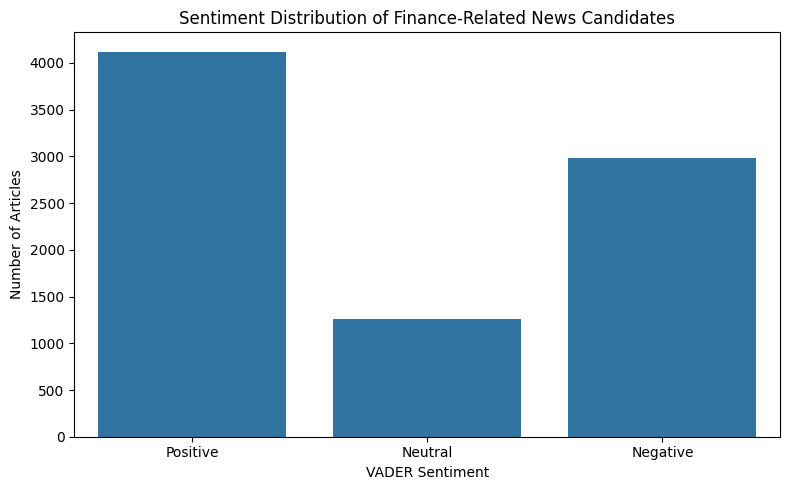

In [13]:
# Visualize sentiment distribution
import matplotlib.pyplot as plt
import seaborn as sns

sentiment_order = ["Positive", "Neutral", "Negative"]

plt.figure(figsize=(8, 5))
sns.countplot(
    data=finance_df,
    x="sentiment",
    order=sentiment_order
)

plt.title("Sentiment Distribution of Finance-Related News Candidates")
plt.xlabel("VADER Sentiment")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

In [14]:
print("MOST POSITIVE-SCORING HEADLINES")
display(
    finance_df.nlargest(10, "compound")[
        ["date", "category", "headline", "compound", "sentiment"]
    ]
)

print("MOST NEGATIVE-SCORING HEADLINES")
display(
    finance_df.nsmallest(10, "compound")[
        ["date", "category", "headline", "compound", "sentiment"]
    ]
)

MOST POSITIVE-SCORING HEADLINES


,date,category,headline,compound,sentiment
187211,2012-09-25,MONEY,Sweet Dreams: Best Credit Cards for Hotel Rewards,0.9850,Positive
119096,2014-10-03,BUSINESS,"It Takes Guts to Share Authentically, But When...",0.9841,Positive
112795,2014-12-14,BUSINESS,It's 2015. How Are We Still Having These Conve...,0.9833,Positive
130884,2014-05-21,WORLDPOST,"In European Elections, Populism is Against Peo...",0.9806,Positive
155011,2013-09-02,BUSINESS,What Is the Optimal Credit Score?,0.9803,Positive
129180,2014-06-10,BUSINESS,Culture Is More Important Than Vision: And We...,0.9797,Positive
164213,2013-05-27,BUSINESS,Will You Be Truly Happy If You Win the Lottery?,0.9788,Positive
101351,2015-04-25,BUSINESS,"It's Not You, It's Me: Are Your Behaviors Hold...",0.9776,Positive
80856,2015-12-13,BUSINESS,Position Yourself for Success Heading Into a N...,0.9775,Positive
181752,2012-11-22,MONEY,Deck the Malls: The 4 Best Credit Cards for Ho...,0.9771,Positive


MOST NEGATIVE-SCORING HEADLINES


,date,category,headline,compound,sentiment
119315,2014-09-30,BUSINESS,The 80/20 View of Anger,-0.9838,Negative
99269,2015-05-19,BUSINESS,Organizational Debt Is Like Technical Debt - B...,-0.9834,Negative
194765,2012-07-05,PARENTING,Parents and Poverty: This Recession Can Hurt f...,-0.9804,Negative
111704,2014-12-26,BUSINESS,Driving Your Startup With Fear Has Bad Consequ...,-0.9796,Negative
166304,2013-05-05,BUSINESS,"Mohammed Sohel Rana, Bangladesh Factory Owner,...",-0.9694,Negative
110284,2015-01-12,BUSINESS,Corporate Violence as Crime: Anniversary of th...,-0.9682,Negative
98533,2015-05-27,BUSINESS,What Your Social Media Picture Says About You,-0.9670,Negative
104746,2015-03-17,BUSINESS,"What's Your R.O.T.? The More You Know, The Mor...",-0.9666,Negative
140650,2014-02-01,BUSINESS,"If You Were a Horrible Boss, Would You Even Kn...",-0.9661,Negative
118138,2014-10-14,BUSINESS,The Deficit Is Down and the Deficit Hawks Are ...,-0.9628,Negative


In [15]:
# Text cleaning

import re
import pandas as pd

# Keep a separate copy so we preserve our existing data
finance_df = finance_df.copy()

def clean_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Keep letters, numbers, apostrophes, and whitespace
    text = re.sub(r"[^a-z0-9\s']", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Clean the combined headline and description
finance_df["clean_text"] = finance_df["text"].fillna("").apply(clean_text)

# Remove records that become empty after cleaning
finance_df = finance_df[
    finance_df["clean_text"].str.len() > 0
].copy()

print("Articles remaining:", len(finance_df))

# Compare original and cleaned text
display(
    finance_df[["text", "clean_text"]].head(10)
)


Articles remaining: 8361


,text,clean_text
56,U.S. Inflation Falls For 2nd Straight Month On...,u s inflation falls for 2nd straight month on ...
91,The Unemployment Insurance System Is Not Ready...,the unemployment insurance system is not ready...
121,U.S. Hiring Slowed In August As Employers Add ...,u s hiring slowed in august as employers add 3...
133,Stocks Dive For Truth Social SPAC Amid Merger ...,stocks dive for truth social spac amid merger ...
162,REI Workers At Berkeley Store Vote To Unionize...,rei workers at berkeley store vote to unionize...
230,Sinema Took Wall Street Money While Killing Ta...,sinema took wall street money while killing ta...
237,Democrats’ Inflation Reduction Act Expected To...,democrats inflation reduction act expected to ...
243,Gas Prices Dip Just Below $4 For The First Tim...,gas prices dip just below 4 for the first time...
259,"‘Come On, Bernie!’ Why Democrats Left Child Ta...",come on bernie why democrats left child tax cr...
261,57 Votes in the Senate: Enough For Private Equ...,57 votes in the senate enough for private equi...


In [16]:
!pip -q install nltk

import nltk

nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

print("NLP preprocessing libraries are ready.")

NLP preprocessing libraries are ready.


In [17]:
# Preprocessing

import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# Keep negation words because they can change sentiment
stop_words.discard("no")
stop_words.discard("not")
stop_words.discard("nor")

# Step 1: Tokenization
finance_df["tokens"] = finance_df["clean_text"].apply(word_tokenize)

# Step 2: Remove stopwords and non-alphabetic tokens
finance_df["filtered_tokens"] = finance_df["tokens"].apply(
    lambda tokens: [
        word for word in tokens
        if word.isalpha() and word not in stop_words
    ]
)

# Convert NLTK POS tags to WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

# Step 3: Lemmatization
def lemmatize_tokens(tokens):
    tagged_tokens = pos_tag(tokens)
    return [
        lemmatizer.lemmatize(word, get_wordnet_pos(tag))
        for word, tag in tagged_tokens
    ]

finance_df["processed_tokens"] = finance_df["filtered_tokens"].apply(
    lemmatize_tokens
)

# Combine processed tokens back into text
finance_df["processed_text"] = finance_df["processed_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

print("Tokenization and lemmatization completed!")
display(
    finance_df[
        ["clean_text", "tokens", "filtered_tokens",
         "processed_tokens", "processed_text"]
    ].head(5)
)


Tokenization and lemmatization completed!


,clean_text,tokens,filtered_tokens,processed_tokens,processed_text
56,u s inflation falls for 2nd straight month on ...,"[u, s, inflation, falls, for, 2nd, straight, m...","[u, inflation, falls, straight, month, lower, ...","[u, inflation, fall, straight, month, lower, g...",u inflation fall straight month lower gas cost...
91,the unemployment insurance system is not ready...,"[the, unemployment, insurance, system, is, not...","[unemployment, insurance, system, not, ready, ...","[unemployment, insurance, system, not, ready, ...",unemployment insurance system not ready next r...
121,u s hiring slowed in august as employers add 3...,"[u, s, hiring, slowed, in, august, as, employe...","[u, hiring, slowed, august, employers, add, jo...","[u, hiring, slow, august, employer, add, job, ...",u hiring slow august employer add job unemploy...
133,stocks dive for truth social spac amid merger ...,"[stocks, dive, for, truth, social, spac, amid,...","[stocks, dive, truth, social, spac, amid, merg...","[stock, dive, truth, social, spac, amid, merge...",stock dive truth social spac amid merger delay...
162,rei workers at berkeley store vote to unionize...,"[rei, workers, at, berkeley, store, vote, to, ...","[rei, workers, berkeley, store, vote, unionize...","[rei, worker, berkeley, store, vote, unionize,...",rei worker berkeley store vote unionize anothe...


In [18]:
# Classify into categories


import re

sector_keywords = {
    "Banking & Credit": [
        "bank", "banking", "credit card", "credit score",
        "loan", "mortgage", "interest rate", "federal reserve",
        "credit monitoring"
    ],
    "Stocks & Investments": [
        "stock", "shares", "investor", "investment", "investing",
        "dividend", "nasdaq", "s&p 500", "dow jones",
        "wall street", "hedge fund", "private equity"
    ],
    "Cryptocurrency": [
        "cryptocurrency", "bitcoin", "ethereum", "crypto"
    ],
    "Corporate Earnings & Finance": [
        "earnings", "revenue", "net profit", "net income",
        "quarterly results", "corporate debt", "bankruptcy",
        "company profit", "company losses"
    ],
    "Economy & Employment": [
        "inflation", "recession", "economic growth",
        "unemployment", "jobs report", "gross domestic product",
        "gdp", "consumer spending", "income inequality",
        "job market"
    ],
    "Taxes & Public Finance": [
        "raising taxes", "tax code", "tax increase", "tax cut",
        "income tax", "budget deficit", "government spending",
        "public finance"
    ],
    "Retirement & Pensions": [
        "pension", "retirement savings", "retirement fund",
        "retirement plan", "social security"
    ],
    "Energy & Commodities": [
        "oil prices", "oil production", "opec", "crude oil",
        "gas prices", "commodity prices", "energy prices"
    ],
    "Personal Finance": [
        "personal finance", "teach kids about money",
        "saving money", "money management", "financial planning",
        "credit card debt", "household budget"
    ],
    "Business & Workplace": [
        "workplace", "employees", "employers", "company",
        "business etiquette", "workplace issue", "small business"
    ],
    "Trade & Foreign Exchange": [
        "trade deficit", "trade war", "exchange rate",
        "foreign exchange", "currency market"
    ]
}

def classify_sector(text):
    text = str(text).lower()
    matched_sectors = []

    for sector, keywords in sector_keywords.items():
        for keyword in keywords:
            pattern = r"\b" + re.escape(keyword) + r"\b"
            if re.search(pattern, text):
                matched_sectors.append(sector)
                break

    return matched_sectors if matched_sectors else [
        "Other / Unclassified"
    ]

finance_df["sectors"] = finance_df["text"].apply(classify_sector)
finance_df["primary_sector"] = finance_df["sectors"].apply(
    lambda sectors: sectors[0]
)

print("Updated sector classification:")
display(
    finance_df["primary_sector"]
    .value_counts()
    .to_frame(name="article_count")
)


Updated sector classification:


,article_count
primary_sector,
Other / Unclassified,5912
Stocks & Investments,639
Business & Workplace,599
Banking & Credit,582
Economy & Employment,305
Corporate Earnings & Finance,133
Energy & Commodities,51
Personal Finance,35
Retirement & Pensions,32


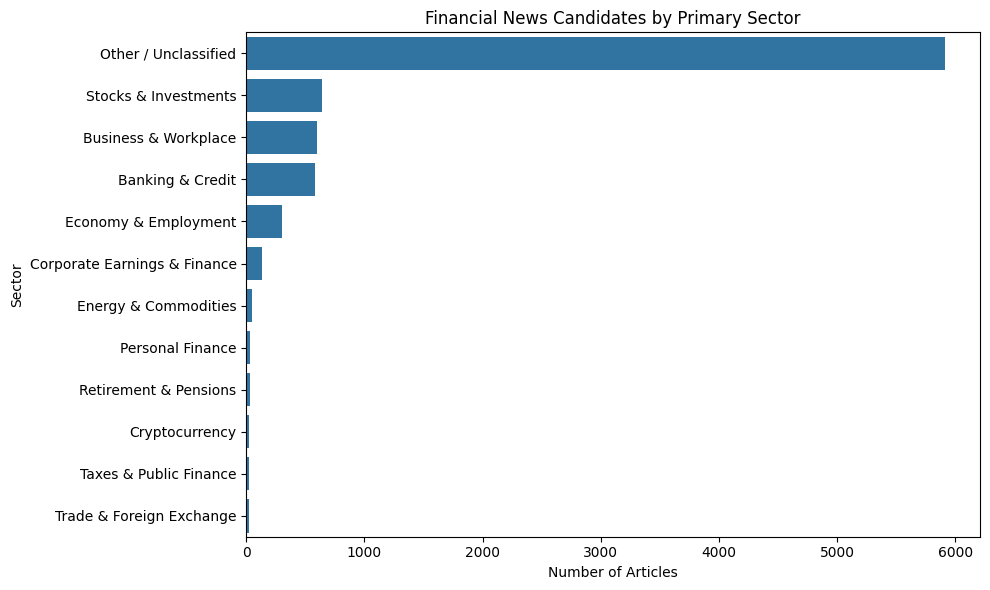

,article_count
primary_sector,
Other / Unclassified,5912
Stocks & Investments,639
Business & Workplace,599
Banking & Credit,582
Economy & Employment,305
Corporate Earnings & Finance,133
Energy & Commodities,51
Personal Finance,35
Retirement & Pensions,32


In [19]:
# Visualize sector distribution

import matplotlib.pyplot as plt
import seaborn as sns

sector_counts = finance_df["primary_sector"].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(
    x=sector_counts.values,
    y=sector_counts.index
)

plt.title("Financial News Candidates by Primary Sector")
plt.xlabel("Number of Articles")
plt.ylabel("Sector")
plt.tight_layout()
plt.show()

display(
    sector_counts.to_frame(name="article_count")
)


,article_count,avg_compound,positive_count,neutral_count,negative_count,positive_pct,neutral_pct,negative_pct
primary_sector,,,,,,,,
Other / Unclassified,5912,0.121,2974,959,1979,50.3,16.2,33.5
Stocks & Investments,639,0.096,314,93,232,49.1,14.6,36.3
Business & Workplace,599,0.139,316,74,209,52.8,12.4,34.9
Banking & Credit,582,0.074,283,64,235,48.6,11.0,40.4
Economy & Employment,305,-0.177,102,13,190,33.4,4.3,62.3
Corporate Earnings & Finance,133,-0.030,52,22,59,39.1,16.5,44.4
Energy & Commodities,51,-0.091,19,8,24,37.3,15.7,47.1
Personal Finance,35,0.276,24,5,6,68.6,14.3,17.1
Retirement & Pensions,32,0.160,19,3,10,59.4,9.4,31.2


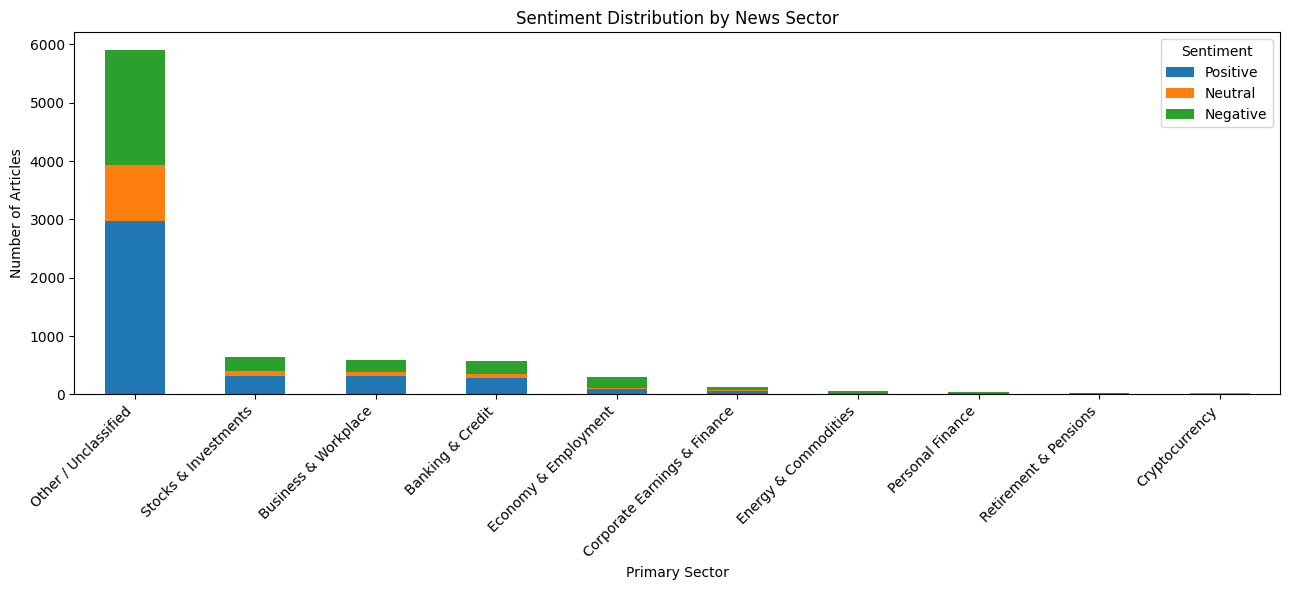

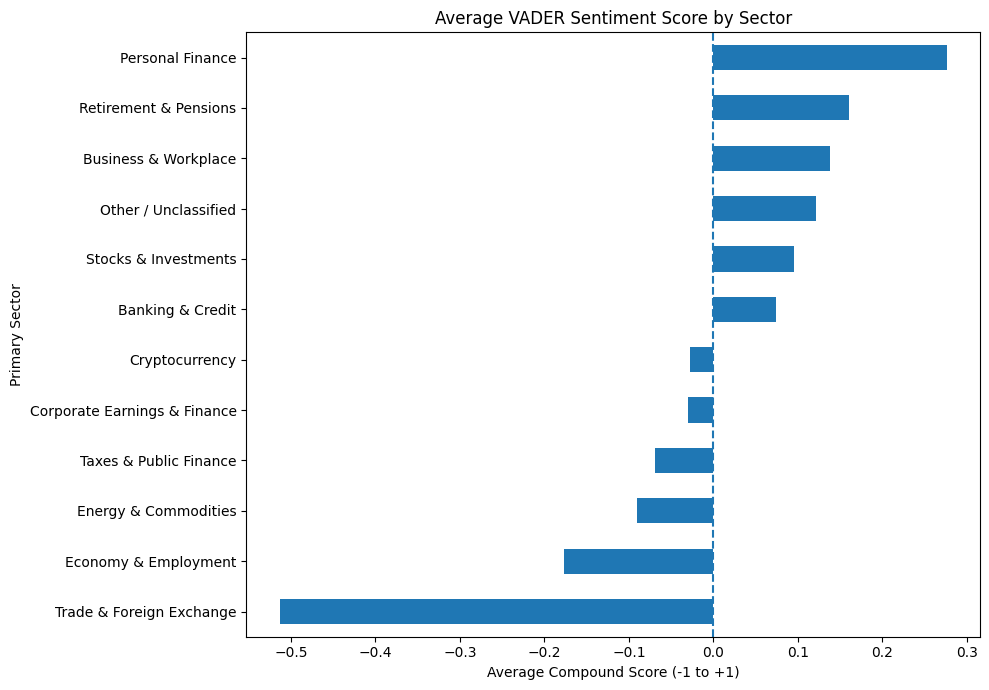

Saved: /content/sector_sentiment_summary.csv


In [20]:

# ==========================================
# SENTIMENT ANALYSIS BY SECTOR
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Summarize sentiment for each sector
sector_sentiment = (
    finance_df.groupby("primary_sector")
    .agg(
        article_count=("sentiment", "size"),
        avg_compound=("compound", "mean"),
        positive_count=("sentiment", lambda x: (x == "Positive").sum()),
        neutral_count=("sentiment", lambda x: (x == "Neutral").sum()),
        negative_count=("sentiment", lambda x: (x == "Negative").sum())
    )
    .sort_values("article_count", ascending=False)
)

# Calculate sentiment percentages
sector_sentiment["positive_pct"] = (
    sector_sentiment["positive_count"]
    / sector_sentiment["article_count"] * 100
).round(1)

sector_sentiment["neutral_pct"] = (
    sector_sentiment["neutral_count"]
    / sector_sentiment["article_count"] * 100
).round(1)

sector_sentiment["negative_pct"] = (
    sector_sentiment["negative_count"]
    / sector_sentiment["article_count"] * 100
).round(1)

# 2. Display summary
display(sector_sentiment.round(3))

# 3. Plot sentiment distribution for the largest sectors
plot_data = (
    finance_df.groupby(["primary_sector", "sentiment"])
    .size()
    .unstack(fill_value=0)
)

plot_data = plot_data.loc[
    sector_sentiment.head(10).index
]

# Keep sentiment columns in a consistent order
sentiment_order = ["Positive", "Neutral", "Negative"]
plot_data = plot_data.reindex(
    columns=sentiment_order, fill_value=0
)

plot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6)
)

plt.title("Sentiment Distribution by News Sector")
plt.xlabel("Primary Sector")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

# 4. Compare average compound scores
avg_scores = sector_sentiment.sort_values("avg_compound")

avg_scores["avg_compound"].plot(
    kind="barh",
    figsize=(10, 7)
)

plt.axvline(x=0, linestyle="--")
plt.title("Average VADER Sentiment Score by Sector")
plt.xlabel("Average Compound Score (-1 to +1)")
plt.ylabel("Primary Sector")
plt.tight_layout()
plt.show()

# 5. Export the summary
sector_sentiment.to_csv(
    "/content/sector_sentiment_summary.csv"
)

print("Saved: /content/sector_sentiment_summary.csv")


## LLM **Integration**

In [21]:
import sys
import transformers
import torch

print("Python:", sys.version)
print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Transformers: 5.18.0
PyTorch: 2.11.0+cpu


In [22]:
from transformers import AutoConfig

model_name = "sshleifer/distilbart-cnn-12-6"

config = AutoConfig.from_pretrained(model_name)
print("Model type:", config.model_type)
print("Model configuration loaded successfully.")

config.json:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

Model type: bart
Model configuration loaded successfully.


In [23]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "sshleifer/distilbart-cnn-12-6"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

print("Tokenizer and summarization model loaded successfully!")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.22GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]

Tokenizer and summarization model loaded successfully!


In [24]:
candidates = finance_df[
    finance_df["short_description"].fillna("").str.len().between(100, 1500)
]

if len(candidates) == 0:
    print("No suitable article descriptions found.")
else:
    article = candidates.iloc[0]

    article_text = (
        str(article["headline"]) + ". " +
        str(article["short_description"])
    )

    inputs = tokenizer(
        article_text,
        return_tensors="pt",
        max_length=1024,
        truncation=True
    )

    summary_ids = model.generate(
        inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        max_new_tokens=80,
        min_new_tokens=20,
        num_beams=2,
        do_sample=False
    )

    summary = tokenizer.decode(
        summary_ids[0],
        skip_special_tokens=True
    )

    print("HEADLINE:")
    print(article["headline"])
    print("\nGENERATED SUMMARY:")
    print(summary)

[transformers] Both `max_new_tokens` (=80) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=20) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


HEADLINE:
The Unemployment Insurance System Is Not Ready For The Next Recession

GENERATED SUMMARY:
 The Unemployment Insurance System is not ready for the next recession . States are cutting back, and Congress is unlikely to step in .


In [25]:
def analyze_news(article_index):
    article = finance_df.loc[article_index]

    headline = str(article["headline"])
    description = str(article["short_description"])
    article_text = headline + ". " + description

    # Existing VADER sentiment result
    sentiment = article["sentiment"]
    compound = article["compound"]

    # Existing rule-based sector classification
    sector = article["primary_sector"]

    # Generate a short summary with DistilBART
    inputs = tokenizer(
        article_text,
        return_tensors="pt",
        max_length=1024,
        truncation=True
    )

    summary_ids = model.generate(
        inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        max_new_tokens=80,
        min_new_tokens=20,
        num_beams=2,
        do_sample=False
    )

    summary = tokenizer.decode(
        summary_ids[0],
        skip_special_tokens=True
    )

    print("=" * 60)
    print("FINANCIAL NEWS INSIGHT")
    print("=" * 60)
    print("\nHeadline:", headline)
    print("Sector:", sector)
    print("Sentiment:", sentiment)
    print("Sentiment score:", round(float(compound), 3))
    print("\nAI-generated summary:")
    print(summary)

In [26]:
model.generation_config.max_length = None
model.generation_config.min_length = None

print(model.generation_config)

GenerationConfig {
  "bos_token_id": 0,
  "decoder_start_token_id": 2,
  "early_stopping": true,
  "eos_token_id": 2,
  "forced_bos_token_id": 0,
  "forced_eos_token_id": 2,
  "length_penalty": 2.0,
  "no_repeat_ngram_size": 3,
  "num_beams": 4,
  "pad_token_id": 1,
  "use_cache": true
}



In [27]:
analyze_news(finance_df.index[10])

FINANCIAL NEWS INSIGHT

Headline: New York Post, Wall Street Journal Editorial Boards Condemn Trump
Sector: Stocks & Investments
Sentiment: Negative
Sentiment score: -0.802

AI-generated summary:
 New York Post, Wall Street Journal editorial boards slam Trump's inaction during Capitol riot . Both publications, owned by Rupert Murdoch, slammed the president's inaction .


## Use Gradio for interactive interface

In [28]:
%pip install -q gradio

In [46]:
import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Reuse your existing processed dataset
app_df = finance_df.copy()

# Preserve the existing dataframe indices used in your notebook
app_df["app_id"] = app_df.index

sectors = ["All Sectors"] + sorted(
    app_df["primary_sector"].dropna().unique().tolist()
)

sentiments = [
    "All Sentiments",
    "Positive",
    "Neutral",
    "Negative"
]


def filter_articles(sector, sentiment, keyword):
    data = app_df.copy()

    if sector != "All Sectors":
        data = data[data["primary_sector"] == sector]

    if sentiment != "All Sentiments":
        data = data[data["sentiment"] == sentiment]

    keyword = (keyword or "").strip()

    if keyword:
        mask = (
            data["headline"].fillna("").str.contains(
                keyword, case=False, regex=False
            )
            | data["short_description"].fillna("").str.contains(
                keyword, case=False, regex=False
            )
        )
        data = data[mask]

    return data


def sentiment_chart(data):
    counts = data["sentiment"].value_counts().reindex(
        ["Positive", "Neutral", "Negative"],
        fill_value=0
    )

    fig, ax = plt.subplots(figsize=(6, 4))
    counts.plot(kind="bar", ax=ax)
    ax.set_title("News Sentiment Distribution")
    ax.set_xlabel("Sentiment")
    ax.set_ylabel("Number of Articles")
    ax.tick_params(axis="x", rotation=0)
    fig.tight_layout()
    return fig


def sector_chart(data):
    counts = data["primary_sector"].value_counts().head(12)

    fig, ax = plt.subplots(figsize=(8, 5))
    counts.sort_values().plot(kind="barh", ax=ax)
    ax.set_title("Financial News by Sector")
    ax.set_xlabel("Number of Articles")
    ax.set_ylabel("Primary Sector")
    fig.tight_layout()
    return fig


def sector_statistics(data):
    if data.empty:
        return pd.DataFrame()

    result = data.groupby("primary_sector").agg(
        Articles=("headline", "size"),
        Average_Sentiment=("compound", "mean"),
        Positive=("sentiment", lambda x: (x == "Positive").sum()),
        Neutral=("sentiment", lambda x: (x == "Neutral").sum()),
        Negative=("sentiment", lambda x: (x == "Negative").sum())
    ).reset_index()

    result["Average_Sentiment"] = (
        result["Average_Sentiment"].round(3)
    )

    return result.sort_values("Articles", ascending=False)


def update_dashboard(sector, sentiment, keyword):
    data = filter_articles(sector, sentiment, keyword)

    if data.empty:
        return (
            "## No matching articles. Try different filters.",
            None,
            None,
            pd.DataFrame(),
            pd.DataFrame(),
            gr.update(choices=[], value=None)
        )

    counts = data["sentiment"].value_counts()

    overview = (
        "## Financial News Dashboard\n\n"
        f"**Articles:** {len(data):,}  \n"
        f"**Positive:** {counts.get('Positive', 0):,}  \n"
        f"**Neutral:** {counts.get('Neutral', 0):,}  \n"
        f"**Negative:** {counts.get('Negative', 0):,}  \n"
        f"**Average VADER score:** {data['compound'].mean():.3f}"
    )

    table = data[
        ["app_id", "headline", "primary_sector", "sentiment", "compound"]
    ].copy()

    table["compound"] = table["compound"].round(3)
    table = table.rename(columns={
        "app_id": "Article ID",
        "headline": "Headline",
        "primary_sector": "Sector",
        "sentiment": "Sentiment",
        "compound": "VADER Score"
    }).head(500)

    choices = [
        (f"{row['headline'][:100]} | {row['sentiment']}", int(idx))
        for idx, row in data.iterrows()
    ]

    return (
        overview,
        sentiment_chart(data),
        sector_chart(data),
        sector_statistics(data),
        table,
        gr.update(
            choices=choices,
            value=choices[0][1] if choices else None
        )
    )


def analyze_article(article_id):
    if article_id is None:
        return "", "", "", "", ""

    article = app_df.loc[int(article_id)]

    return (
        str(article["headline"]),
        str(article["short_description"]),
        str(article["primary_sector"]),
        str(article["sentiment"]),
        f"{float(article['compound']):.3f}"
    )


def generate_summary(article_id):
    if article_id is None:
        return "Select an article first."

    article = app_df.loc[int(article_id)]

    text = (
        str(article["headline"]) + ". " +
        str(article["short_description"])
    ).strip()

    try:
        model.eval()

        inputs = tokenizer(
            text,
            return_tensors="pt",
            max_length=1024,
            truncation=True
        )

        # Support either CPU or GPU model placement
        device = next(model.parameters()).device
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            output = model.generate(
                **inputs,
                max_new_tokens=80,
                num_beams=2,
                do_sample=False
            )

        summary = tokenizer.decode(
            output[0],
            skip_special_tokens=True
        )

        return "### AI-Generated Summary\n\n" + summary

    except Exception as e:
        return f"Summary error: {type(e).__name__}: {e}"


with gr.Blocks(
    title="Financial News Insight Analyzer",
    theme=gr.themes.Soft()
) as demo:

    gr.Markdown(
        """
        # Financial News Insight Analyzer

        Explore financial news through sentiment analysis, sector
        classification, and AI-powered summarization.

        *Sentiment scores describe article language, not future
        market performance or investment recommendations.*
        """
    )

    with gr.Row():
        sector_filter = gr.Dropdown(
            choices=sectors,
            value="All Sectors",
            label="News Sector"
        )

        sentiment_filter = gr.Dropdown(
            choices=sentiments,
            value="All Sentiments",
            label="Sentiment"
        )

    search_box = gr.Textbox(
        label="Search Articles",
        placeholder="Search headlines or descriptions..."
    )

    refresh_button = gr.Button(
        "Update Dashboard",
        variant="primary"
    )

    overview = gr.Markdown()

    with gr.Tab("Dashboard"):
        with gr.Row():
            sentiment_plot = gr.Plot()
            sector_plot = gr.Plot()

        statistics = gr.Dataframe(
            label="Sentiment Statistics by Sector",
            interactive=False
        )

    with gr.Tab("Article Explorer"):
        article_table = gr.Dataframe(
            label="Matching Financial News",
            interactive=False
        )

        article_picker = gr.Dropdown(
            label="Select an Article",
            choices=[]
        )

        analyze_button = gr.Button("View Article Details")

        headline_out = gr.Textbox(label="Headline")
        description_out = gr.Textbox(
            label="Description",
            lines=4
        )

        with gr.Row():
            sector_out = gr.Textbox(label="Primary Sector")
            sentiment_out = gr.Textbox(label="Sentiment")
            score_out = gr.Textbox(label="VADER Compound Score")

        summary_button = gr.Button("Generate AI Summary")
        summary_out = gr.Markdown()

    dashboard_outputs = [
        overview,
        sentiment_plot,
        sector_plot,
        statistics,
        article_table,
        article_picker
    ]

    refresh_button.click(
        update_dashboard,
        inputs=[sector_filter, sentiment_filter, search_box],
        outputs=dashboard_outputs
    )

    sector_filter.change(
        update_dashboard,
        inputs=[sector_filter, sentiment_filter, search_box],
        outputs=dashboard_outputs
    )

    sentiment_filter.change(
        update_dashboard,
        inputs=[sector_filter, sentiment_filter, search_box],
        outputs=dashboard_outputs
    )

    search_box.submit(
        update_dashboard,
        inputs=[sector_filter, sentiment_filter, search_box],
        outputs=dashboard_outputs
    )

    analyze_button.click(
        analyze_article,
        inputs=article_picker,
        outputs=[
            headline_out,
            description_out,
            sector_out,
            sentiment_out,
            score_out
        ]
    )

    summary_button.click(
        generate_summary,
        inputs=article_picker,
        outputs=summary_out
    )

    demo.load(
        update_dashboard,
        inputs=[sector_filter, sentiment_filter, search_box],
        outputs=dashboard_outputs
    )

demo.launch(share=True)

/tmp/ipykernel_2060/271160560.py:210: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7060d8e15741accb99.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
